# 2018 — Graph Attention Networks (GAT)

**Papers:** Petar Veličković, Guillem Cucurull, Arantxa Casanova, Adriana Romero, Pietro Liò & Yoshua Bengio, *"Graph Attention Networks"*, ICLR (2018). Follow-up: Shaked Brody, Uri Alon & Eran Yahav, *"How Attentive are Graph Attention Networks?"* (GATv2), ICLR (2022).

A GCN (notebook 33) averages a node's neighbours with **fixed** weights given by the graph's degrees. Every neighbour counts the same, whether it is relevant or not. A GAT lets each node **learn how much to listen to each neighbour**, with attention restricted to the graph's edges:

$$e_{ij} = \operatorname{LeakyReLU}\big(a^\top[W h_i \,\Vert\, W h_j]\big), \qquad \alpha_{ij} = \operatorname{softmax}_{j\in\mathcal N(i)}(e_{ij}), \qquad h_i' = \sigma\Big(\sum_{j\in\mathcal N(i)} \alpha_{ij} W h_j\Big)$$

with several heads, as in the Transformer (notebook 37). A Transformer is in fact a GAT on a fully connected graph, with dot-product scores instead of the additive score above.

**GATv2** noticed a weakness in this score. Because $a^\top[Wh_i\Vert Wh_j] = a_1^\top Wh_i + a_2^\top Wh_j$ and LeakyReLU is monotonic, every node ranks its neighbours in the **same order**, determined by $a_2^\top Wh_j$ alone. GAT's attention is "static". GATv2 applies the nonlinearity before the final projection, $e_{ij} = a^\top\operatorname{LeakyReLU}(W[h_i\Vert h_j])$, which makes the ranking depend on the query node ("dynamic attention").

**Test:** the 4-community graph from notebook 33, with an increasing fraction of **noisy edges** between communities. A useful attention should down-weight neighbours from other communities.

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
def make_graph(noise_frac, n_per=100, K=4, avg_deg=10, feat_signal=0.6, seed=0):
    """Communities; each node gets avg_deg edges, a fraction noise_frac of them to other communities."""
    g = torch.Generator().manual_seed(seed)
    N = n_per * K; labels = torch.arange(K).repeat_interleave(n_per)
    A = torch.zeros(N, N)
    for i in range(N):
        n_noise = int(round(avg_deg / 2 * noise_frac)); n_in = avg_deg // 2 - n_noise
        same = torch.where(labels == labels[i])[0]; other = torch.where(labels != labels[i])[0]
        A[i, same[torch.randint(len(same), (n_in,), generator=g)]] = 1; A[i, other[torch.randint(len(other), (n_noise,), generator=g)]] = 1
    A = ((A + A.T) > 0).float(); A.fill_diagonal_(0)
    X = torch.randn(K, 32, generator=g)[labels] * feat_signal + torch.randn(N, 32, generator=g)
    train = torch.cat([torch.where(labels == k)[0][:20] for k in range(K)])
    test = torch.ones(N, dtype=torch.bool); test[train] = False
    return A.to(device), X.to(device), labels.to(device), train.to(device), test.to(device)

class GCN(nn.Module):
    def __init__(self, d_in, d_out, h=64):
        super().__init__(); self.l1, self.l2 = nn.Linear(d_in, h), nn.Linear(h, d_out)
    def forward(self, X, A):
        Ah = A + torch.eye(len(A), device=A.device); d = Ah.sum(1).pow(-0.5); An = d[:, None] * Ah * d[None]
        return An @ self.l2(F.dropout(F.elu(An @ self.l1(F.dropout(X, 0.5, self.training))), 0.5, self.training))

class GATLayer(nn.Module):
    def __init__(self, d_in, d_out, heads, v2=False, concat=True):
        super().__init__(); self.h, self.d, self.v2, self.concat = heads, d_out, v2, concat
        if v2:
            self.Wl, self.Wr = nn.Linear(d_in, heads * d_out), nn.Linear(d_in, heads * d_out)
        else:
            self.W = nn.Linear(d_in, heads * d_out, bias=False)
            self.a_src, self.a_dst = nn.Parameter(torch.randn(heads, d_out) * 0.1), nn.Parameter(torch.randn(heads, d_out) * 0.1)
        if v2: self.a = nn.Parameter(torch.randn(heads, d_out) * 0.1)
    def forward(self, X, A):
        N = len(X); mask = (A + torch.eye(N, device=A.device)) > 0                # attend over neighbours and self
        if self.v2:
            hl, hr = self.Wl(X).view(N, self.h, self.d), self.Wr(X).view(N, self.h, self.d)
            e = (F.leaky_relu(hr[:, None] + hl[None, :], 0.2) * self.a).sum(-1)     # (i, j, heads): nonlinearity BEFORE a
            msg = hl
        else:
            Wh = self.W(X).view(N, self.h, self.d)
            e = F.leaky_relu((Wh * self.a_dst).sum(-1)[:, None] + (Wh * self.a_src).sum(-1)[None, :], 0.2)   # a1·Wh_i + a2·Wh_j
            msg = Wh
        e = e.masked_fill(~mask[..., None], float("-inf"))
        alpha = F.softmax(e, dim=1)                                           # normalise over neighbours j
        self.alpha = alpha.detach()
        out = torch.einsum("ijh,jhd->ihd", F.dropout(alpha, 0.3, self.training), msg)
        return out.reshape(N, -1) if self.concat else out.mean(1)

class GAT(nn.Module):
    def __init__(self, d_in, d_out, v2=False, h=8, heads=8):
        super().__init__(); self.l1 = GATLayer(d_in, h, heads, v2); self.l2 = GATLayer(h * heads, d_out, 1, v2, concat=False)
    def forward(self, X, A):
        return self.l2(F.dropout(F.elu(self.l1(F.dropout(X, 0.5, self.training), A)), 0.5, self.training), A)

class MLP(nn.Module):
    def __init__(self, d_in, d_out, h=64):
        super().__init__(); self.net = nn.Sequential(nn.Dropout(0.5), nn.Linear(d_in, h), nn.ELU(), nn.Dropout(0.5), nn.Linear(h, d_out))
    def forward(self, X, A): return self.net(X)

def fit(model, A, X, y, train, test, epochs=300, seed=0):
    seed_everything(seed); model = model.to(device); opt = torch.optim.Adam(model.parameters(), lr=5e-3, weight_decay=5e-4)
    for _ in range(epochs):
        model.train(); loss = F.cross_entropy(model(X, A)[train], y[train]); opt.zero_grad(); loss.backward(); opt.step()
    model.eval()
    with torch.no_grad(): return (model(X, A).argmax(1)[test] == y[test]).float().mean().item(), model

inter-community edges   0%: MLP (no graph) 0.939  GCN 1.000  GAT 1.000  GATv2 1.000


inter-community edges  20%: MLP (no graph) 0.940  GCN 0.999  GAT 0.998  GATv2 0.999


inter-community edges  40%: MLP (no graph) 0.940  GCN 0.985  GAT 0.972  GATv2 0.992


inter-community edges  60%: MLP (no graph) 0.940  GCN 0.768  GAT 0.754  GATv2 0.898


inter-community edges  70%: MLP (no graph) 0.940  GCN 0.476  GAT 0.436  GATv2 0.543


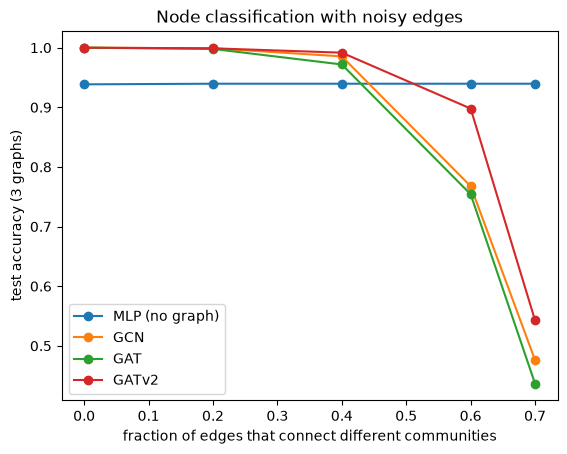

In [3]:
noise_levels = [0.0, 0.2, 0.4, 0.6, 0.7]
makers = {"MLP (no graph)": MLP, "GCN": GCN, "GAT": lambda a, b: GAT(a, b), "GATv2": lambda a, b: GAT(a, b, v2=True)}
res = {k: [] for k in makers}
for nf in noise_levels:
    accs = {k: [] for k in makers}
    for seed in range(3):
        A, X, y, tr, te = make_graph(nf, seed=seed)
        for k, mk in makers.items(): accs[k].append(fit(mk(32, 4), A, X, y, tr, te, seed=seed)[0])
    for k in makers: res[k].append(np.mean(accs[k]))
    print(f"inter-community edges {nf:4.0%}: " + "  ".join(f"{k} {np.mean(v):.3f}" for k, v in accs.items()))
for k, v in res.items(): plt.plot(noise_levels, v, marker="o", label=k)
plt.xlabel("fraction of edges that connect different communities"); plt.ylabel("test accuracy (3 graphs)"); plt.legend(); plt.title("Node classification with noisy edges"); plt.show()

## Where does the attention go?
On the graph with 40% noisy edges: how much attention mass (first layer, averaged over heads and nodes) lands on neighbours from the **same** community, compared with the fraction of same-community neighbours (what uniform averaging would give)?

In [4]:
A, X, y, tr, te = make_graph(0.4, seed=0)
same = (y[:, None] == y[None, :]).float(); nbr = ((A + torch.eye(len(A), device=device)) > 0).float()
print(f"same-community share of neighbours (uniform weights): {((same * nbr).sum(1) / nbr.sum(1)).mean().item():.3f}")
for name, v2 in [("GAT", False), ("GATv2", True)]:
    acc, m = fit(GAT(32, 4, v2=v2), A, X, y, tr, te)
    with torch.no_grad(): m(X, A)
    alpha = m.l1.alpha.mean(-1)
    print(f"{name:5s} attention mass on same-community neighbours: {(alpha * same).sum(1).mean().item():.3f}   (test acc {acc:.3f})")

same-community share of neighbours (uniform weights): 0.636


GAT   attention mass on same-community neighbours: 0.654   (test acc 0.988)


GATv2 attention mass on same-community neighbours: 0.722   (test acc 0.994)


## Takeaways
- **Learned neighbour weights, measured.** With 40% noisy edges, GAT's attention puts 0.65 of its mass on same-community neighbours, barely above the 0.64 that uniform averaging gives, and GAT tracks GCN closely at every noise level. GATv2 moves the mass to 0.72 and holds up much better at 60% noise (0.90 vs. 0.77 for GCN).
- **When most edges are wrong** (70%), every graph model falls below the MLP that ignores the graph: message passing assumes neighbours are informative (homophily), and attention can only partly undo a bad graph.
- **Static vs. dynamic attention:** GATv1's additive score gives every node the same neighbour ranking; GATv2 fixes it with one reordering of operations. Measure attention, do not assume it.
- **Message passing + attention** is the template for graph Transformers and for models such as AlphaFold 2's structure module (attention over residue pairs) and GraphCast (weather forecasting with message passing on a mesh).